# Test thermal kernel SVM

This notebook tests `run_thermal_kernel_svm.py`.


In [4]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np

cwd = Path.cwd()
script_dir = cwd if (cwd / "run_thermal_kernel_svm.py").exists() else cwd / "scripts"
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

import run_thermal_kernel_svm as thermal_svm
importlib.reload(thermal_svm)

from data_config import available_thermal_betas, available_thermal_l_values
from run_thermal_kernel_svm import run_thermal_kernel_svm_beta_sweep, thermal_svm_results_table
from plot_gram_matrices import IPR_GRAM_CMAP

# print("Using:", thermal_svm.__file__)
%matplotlib inline

## Thermal SVM process

1. The processed thermal data are available for `L = 20, 50, 100`.
2. For each beta value, load the thermal IPR and HS Gram matrices `K(h_a, h_b; beta)`.
3. Assign phase labels by comparing `h` to the critical point: label `0` for `h < h_c` and label `1` for `h >= h_c`, with default `h_c = 1.0`.
4. Split each precomputed kernel into train/test blocks and train `SVC(kernel="precomputed", class_weight="balanced")`.
5. Average balanced accuracy over repeated train/test splits.
6. Plot IPR and HS on the same axes, with beta reversed from large to small.

The solid curves are global balanced accuracy. The dashed curves are local balanced accuracy near the phase boundary.


## Available processed thermal data


In [5]:
for kind in ["ipr", "hs"]:
    L_values = available_thermal_l_values(kind=kind, source="processed")
    print(kind.upper(), "L values:", L_values)
    for L in L_values:
        betas = available_thermal_betas(kind=kind, L=L, source="processed")
        print(f"  L={L}: {len(betas)} betas, first={betas[0]:g}, last={betas[-1]:g}")

IPR L values: [20, 50, 100]
  L=20: 20 betas, first=0.1, last=2
  L=50: 20 betas, first=0.1, last=2
  L=100: 20 betas, first=0.1, last=2
HS L values: [20, 50, 100]
  L=20: 20 betas, first=0.1, last=2
  L=50: 20 betas, first=0.1, last=2
  L=100: 20 betas, first=0.1, last=2


## Combined IPR/HS beta sweep for L=20, 50, 100


THERMAL experiment: L=20, source=processed, kinds=['ipr', 'hs']

IPR kernel:
beta=0.1: global = 0.9623 +/- 0.0092; local = 0.6695 +/- 0.0069
beta=0.2: global = 0.9895 +/- 0.0033; local = 0.8047 +/- 0.0130
beta=0.3: global = 0.9938 +/- 0.0029; local = 0.8565 +/- 0.0116
beta=0.4: global = 0.9965 +/- 0.0034; local = 0.8988 +/- 0.0151
beta=0.5: global = 0.9967 +/- 0.0029; local = 0.9215 +/- 0.0152
beta=0.6: global = 0.9970 +/- 0.0026; local = 0.9275 +/- 0.0112
beta=0.7: global = 0.9975 +/- 0.0024; local = 0.9395 +/- 0.0062
beta=0.8: global = 0.9972 +/- 0.0022; local = 0.9450 +/- 0.0075
beta=0.9: global = 0.9975 +/- 0.0024; local = 0.9475 +/- 0.0089
beta=1: global = 0.9978 +/- 0.0022; local = 0.9510 +/- 0.0091
beta=1.1: global = 0.9978 +/- 0.0022; local = 0.9543 +/- 0.0064
beta=1.2: global = 0.9978 +/- 0.0022; local = 0.9543 +/- 0.0072
beta=1.3: global = 0.9980 +/- 0.0023; local = 0.9580 +/- 0.0077
beta=1.4: global = 0.9978 +/- 0.0022; local = 0.9535 +/- 0.0082
beta=1.5: global = 0.9978 +/-

,kind,beta,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,ipr,0.1,0.96225,0.009238,0.66950,0.006852
1,ipr,0.2,0.98950,0.003291,0.80475,0.013041
2,ipr,0.3,0.99375,0.002946,0.85650,0.011559
3,ipr,0.4,0.99650,0.003375,0.89875,0.015150
4,ipr,0.5,0.99675,0.002899,0.92150,0.015193
5,ipr,0.6,0.99700,0.002582,0.92750,0.011242
6,ipr,0.7,0.99750,0.002357,0.93950,0.006214
7,ipr,0.8,0.99725,0.002189,0.94500,0.007546
8,ipr,0.9,0.99750,0.002357,0.94750,0.008898
9,ipr,1.0,0.99775,0.002189,0.95100,0.009144


THERMAL experiment: L=50, source=processed, kinds=['ipr', 'hs']

IPR kernel:
beta=0.1: global = 0.9868 +/- 0.0039; local = 0.7932 +/- 0.0122
beta=0.2: global = 0.9948 +/- 0.0034; local = 0.8725 +/- 0.0162
beta=0.3: global = 0.9970 +/- 0.0026; local = 0.9217 +/- 0.0120
beta=0.4: global = 0.9972 +/- 0.0022; local = 0.9465 +/- 0.0087
beta=0.5: global = 0.9980 +/- 0.0023; local = 0.9578 +/- 0.0081
beta=0.6: global = 0.9980 +/- 0.0023; local = 0.9718 +/- 0.0090
beta=0.7: global = 0.9982 +/- 0.0024; local = 0.9753 +/- 0.0086
beta=0.8: global = 0.9980 +/- 0.0023; local = 0.9582 +/- 0.0074
beta=0.9: global = 0.9982 +/- 0.0024; local = 0.9745 +/- 0.0071
beta=1: global = 0.9985 +/- 0.0024; local = 0.9762 +/- 0.0056
beta=1.1: global = 0.9985 +/- 0.0024; local = 0.9765 +/- 0.0060
beta=1.2: global = 0.9982 +/- 0.0024; local = 0.9745 +/- 0.0054
beta=1.3: global = 0.9988 +/- 0.0021; local = 0.9925 +/- 0.0044
beta=1.4: global = 0.9988 +/- 0.0021; local = 0.9822 +/- 0.0055
beta=1.5: global = 0.9988 +/-

,kind,beta,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,ipr,0.1,0.98675,0.003918,0.79325,0.012193
1,ipr,0.2,0.99475,0.003426,0.87250,0.016159
2,ipr,0.3,0.99700,0.002582,0.92175,0.011963
3,ipr,0.4,0.99725,0.002189,0.94650,0.008676
4,ipr,0.5,0.99800,0.002297,0.95775,0.008118
5,ipr,0.6,0.99800,0.002297,0.97175,0.008979
6,ipr,0.7,0.99825,0.002372,0.97525,0.008616
7,ipr,0.8,0.99800,0.002297,0.95825,0.007365
8,ipr,0.9,0.99825,0.002372,0.97450,0.007051
9,ipr,1.0,0.99850,0.002415,0.97625,0.005559


THERMAL experiment: L=100, source=processed, kinds=['ipr', 'hs']

IPR kernel:
beta=0.1: global = 0.9923 +/- 0.0046; local = 0.8082 +/- 0.0092
beta=0.2: global = 0.9967 +/- 0.0029; local = 0.9215 +/- 0.0131
beta=0.3: global = 0.9978 +/- 0.0022; local = 0.9557 +/- 0.0084
beta=0.4: global = 0.9980 +/- 0.0023; local = 0.9575 +/- 0.0085
beta=0.5: global = 0.9985 +/- 0.0024; local = 0.9885 +/- 0.0072
beta=0.6: global = 0.9980 +/- 0.0023; local = 0.9607 +/- 0.0046
beta=0.7: global = 0.9980 +/- 0.0023; local = 0.9685 +/- 0.0053
beta=0.8: global = 0.9988 +/- 0.0021; local = 0.9803 +/- 0.0042
beta=0.9: global = 0.9988 +/- 0.0021; local = 0.9892 +/- 0.0053
beta=1: global = 0.9988 +/- 0.0021; local = 0.9810 +/- 0.0038
beta=1.1: global = 0.9995 +/- 0.0011; local = 0.9970 +/- 0.0020
beta=1.2: global = 0.9980 +/- 0.0023; local = 0.9705 +/- 0.0051
beta=1.3: global = 0.9988 +/- 0.0021; local = 0.9862 +/- 0.0032
beta=1.4: global = 0.9980 +/- 0.0023; local = 0.9633 +/- 0.0057
beta=1.5: global = 0.9982 +/

,kind,beta,global_bal_acc_mean,global_bal_acc_std,local_bal_acc_mean,local_bal_acc_std
0,ipr,0.1,0.99225,0.004632,0.80825,0.009208
1,ipr,0.2,0.99675,0.002899,0.92150,0.013134
2,ipr,0.3,0.99775,0.002189,0.95575,0.008420
3,ipr,0.4,0.99800,0.002297,0.95750,0.008498
4,ipr,0.5,0.99850,0.002415,0.98850,0.007188
5,ipr,0.6,0.99800,0.002297,0.96075,0.004572
6,ipr,0.7,0.99800,0.002297,0.96850,0.005297
7,ipr,0.8,0.99875,0.002125,0.98025,0.004158
8,ipr,0.9,0.99875,0.002125,0.98925,0.005277
9,ipr,1.0,0.99875,0.002125,0.98100,0.003764


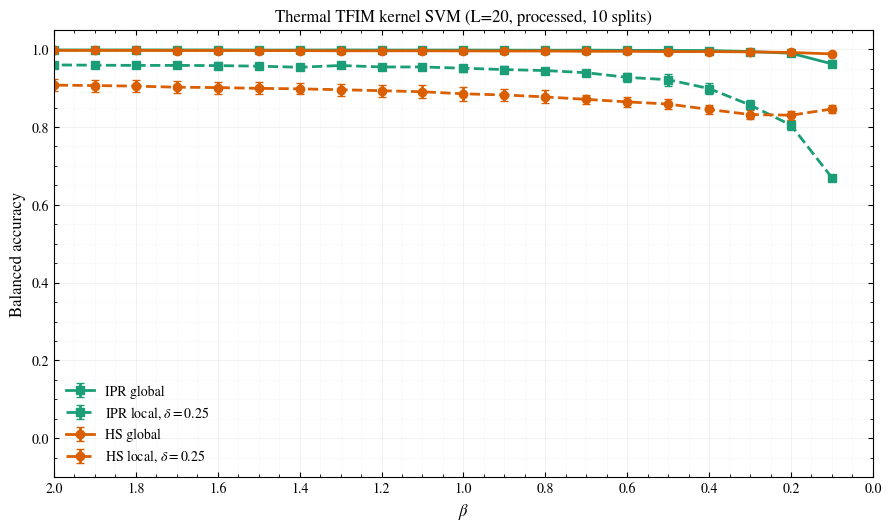

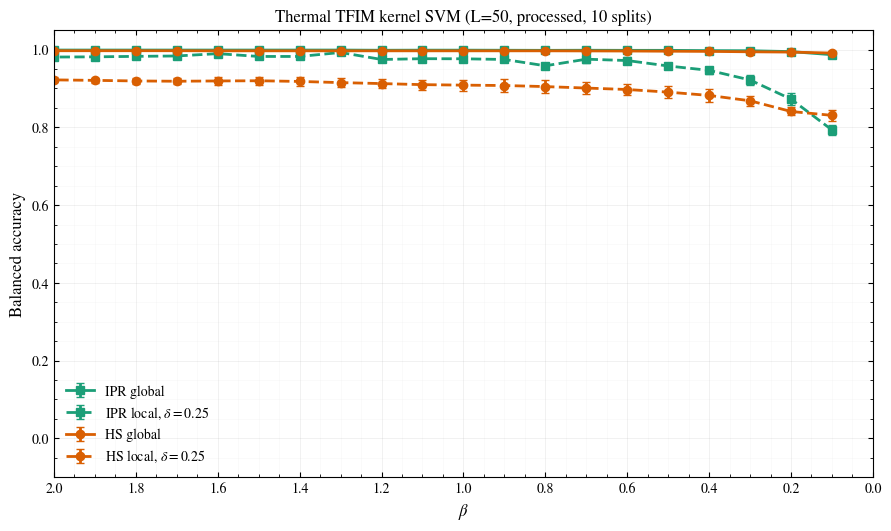

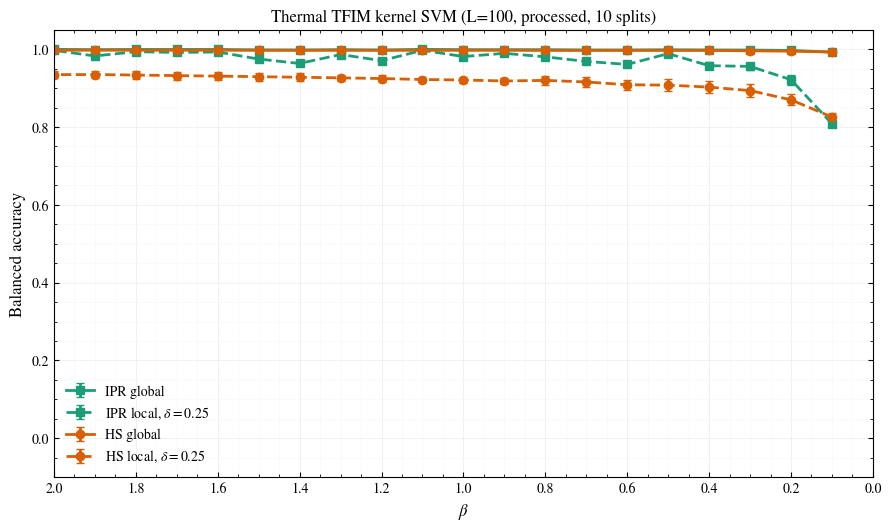

In [6]:
thermal_L_values = [20, 50, 100]
results_by_L = {}

for L in thermal_L_values:
    fig, ax, results = run_thermal_kernel_svm_beta_sweep(
        L=L,
        kinds=("ipr", "hs"),
        source="processed",
        test_frac=0.10,
        local_delta=0.25,
        n_splits=10,
        rng_seed=12345,
        C=1.0,
    )
    results_by_L[L] = results
    display(thermal_svm_results_table(results))

results_L20 = results_by_L[20]
results_L50 = results_by_L[50]
results_L100 = results_by_L[100]